In [15]:
%matplotlib inline
import pandas as pd
import tmap as tm
from mhfp.encoder import MHFPEncoder
from faerun import Faerun
from rdkit import Chem
from map4 import MAP4Calculator
from timeit import default_timer as timer
import pickle
from sklearn.cluster import AgglomerativeClustering
from faerun import Faerun
import numpy as np
import json
import pandas as pd
from matplotlib import pyplot as plt
folder = 'v2_files/'

In [16]:
# The number of permutations used by the MinHashing algorithm
perm = 1024

# Initializing the MHFP encoder with 512 permutations
enc = MHFPEncoder(perm)

# Initialize the LSH Forest
lf = tm.LSHForest(perm)

In [18]:
matrix = pd.read_csv('similarity_matrix_geass.csv').rename(columns={'Unnamed: 0': ''}).set_index('')
matrix

,SF_0293,SF_0298,SF_0446,SF_0197,BS_0894,BS_1574,SF_0068,SF_0401,BS_1033,BS_0042,...,SF_0707,SF_0713,SF_0708,SF_0716,SF_0706,SF_0692,SF_0690,SF_0719,SF_0714,SF_0681
,,,,,,,,,,,,,,,,,,,,,
SF_0293,0.000000,0.620117,0.538086,0.927734,0.994141,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,0.999023,0.995117,0.997070,1.000000,1.000000,0.992188
SF_0298,0.620117,0.000000,0.755859,0.955078,0.995117,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,0.999023,0.999023,1.000000,1.000000,1.000000,0.994141
SF_0446,0.538086,0.755859,0.000000,0.962891,0.995117,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,0.999023,0.990234,0.991211,1.000000,1.000000,0.990234
SF_0197,0.927734,0.955078,0.962891,0.000000,0.996094,0.999023,0.999023,0.988281,0.999023,0.986328,...,0.993164,0.993164,0.993164,0.991211,0.986328,0.976562,0.971680,0.999023,0.992188,0.981445
BS_0894,0.994141,0.995117,0.995117,0.996094,0.000000,0.999023,0.989258,0.988281,0.984375,0.994141,...,0.989258,0.992188,0.990234,0.993164,0.988281,0.994141,0.994141,0.993164,0.993164,0.999023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SF_0692,0.995117,0.999023,0.990234,0.976562,0.994141,0.940430,0.948242,0.884766,0.995117,0.980469,...,0.877930,0.886719,0.884766,0.856445,0.841797,0.000000,0.577148,0.987305,0.888672,0.991211
SF_0690,0.997070,1.000000,0.991211,0.971680,0.994141,0.930664,0.952148,0.852539,0.994141,0.978516,...,0.874023,0.877930,0.873047,0.864258,0.833984,0.577148,0.000000,0.988281,0.877930,0.995117
SF_0719,1.000000,1.000000,1.000000,0.999023,0.993164,0.971680,0.985352,0.994141,0.992188,0.986328,...,0.987305,0.983398,0.987305,0.976562,0.988281,0.987305,0.988281,0.000000,0.985352,0.999023


In [19]:
edge_list = []
for i, row in enumerate(matrix.iterrows()):
    for j, (index, value) in enumerate(row[1][i+1:].iteritems()):
        k=i+1+j
        if value == 1.0:
            continue
        edge_list.append([i, k, value])

In [20]:
edge_list[2000:3000]

[[2, 1012, 0.974609375],
 [2, 1013, 0.98046875],
 [2, 1014, 0.9697265625],
 [2, 1015, 0.9677734375],
 [2, 1018, 0.9794921875],
 [2, 1019, 0.9814453125],
 [2, 1020, 0.9814453125],
 [2, 1021, 0.984375],
 [2, 1023, 0.9931640625],
 [2, 1024, 0.9912109375],
 [2, 1029, 0.9990234375],
 [2, 1030, 0.9990234375],
 [2, 1031, 0.9912109375],
 [2, 1032, 0.927734375],
 [2, 1034, 0.9892578125],
 [2, 1036, 0.9951171875],
 [2, 1039, 0.927734375],
 [2, 1040, 0.9208984375],
 [2, 1041, 0.9970703125],
 [2, 1048, 0.998046875],
 [2, 1049, 0.998046875],
 [2, 1054, 0.9736328125],
 [2, 1055, 0.9677734375],
 [2, 1056, 0.9990234375],
 [2, 1057, 0.9990234375],
 [2, 1058, 0.9990234375],
 [2, 1060, 0.9990234375],
 [2, 1061, 0.9990234375],
 [2, 1064, 0.9931640625],
 [2, 1065, 0.99609375],
 [2, 1066, 0.94140625],
 [2, 1067, 0.990234375],
 [2, 1072, 0.982421875],
 [2, 1073, 0.9990234375],
 [2, 1075, 0.9990234375],
 [2, 1084, 0.9990234375],
 [2, 1086, 0.9990234375],
 [2, 1089, 0.9931640625],
 [2, 1091, 0.9931640625],
 [2

In [7]:
edge_list = [item for item in edge_list if item[2] >= 0.8]

In [8]:
#prueba pequeña
edge_list2 = [item for item in edge_list if item[2] >= 0.9]

In [9]:
#tamaño prueba
len(edge_list2)

150

In [10]:
edge_list[1:100]

[[11, 89, 0.84765625],
 [11, 320, 0.806640625],
 [11, 607, 0.822265625],
 [11, 608, 0.8212890629999999],
 [21, 124, 0.9716796879999999],
 [29, 537, 0.859375],
 [29, 538, 0.8466796879999999],
 [29, 1237, 0.86328125],
 [32, 170, 0.9384765629999999],
 [32, 266, 0.8125],
 [32, 269, 0.8740234379999999],
 [32, 270, 0.8251953129999999],
 [32, 277, 0.818359375],
 [32, 290, 0.9326171879999999],
 [32, 299, 0.8623046879999999],
 [32, 350, 0.8525390629999999],
 [32, 571, 0.9384765629999999],
 [32, 884, 0.9091796879999999],
 [32, 885, 0.9384765629999999],
 [32, 1207, 0.9384765629999999],
 [41, 166, 0.8203125],
 [42, 68, 0.8212890629999999],
 [42, 70, 0.8076171879999999],
 [42, 257, 0.8076171879999999],
 [42, 390, 0.8076171879999999],
 [42, 452, 0.8076171879999999],
 [42, 458, 0.8076171879999999],
 [42, 812, 0.8212890629999999],
 [49, 73, 0.8662109379999999],
 [68, 72, 0.8212890629999999],
 [68, 811, 0.8212890629999999],
 [68, 813, 0.8212890629999999],
 [68, 860, 0.8212890629999999],
 [70, 72, 0.807

In [21]:
x, y, s, t, _ = tm.layout_from_edge_list(1853, edge_list, create_mst=True)

<IPython.core.display.Javascript object>


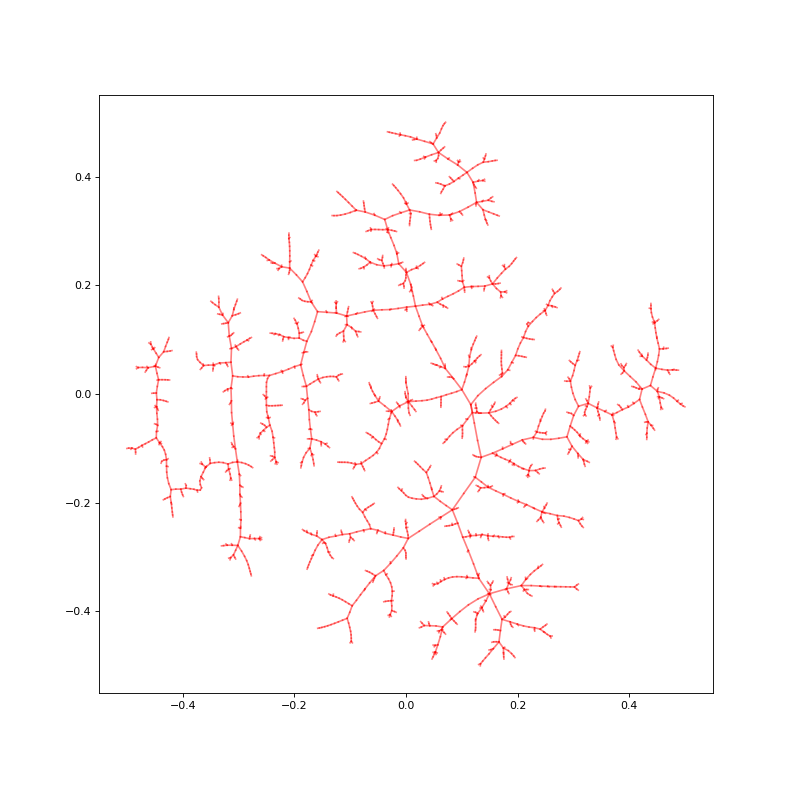

In [22]:
%matplotlib notebook
_, ax1 = plt.subplots(figsize=(10,10))
for i in range(len(s)):
    ax1.plot(
        [x[s[i]], x[t[i]]],
        [y[s[i]], y[t[i]]],
        "r-",
        alpha=0.5,
        zorder=2,
    )

In [23]:
with open('v2_files/original_molecules_Feb23.pkl', 'rb') as f:
    original_molecules = pickle.load(f)

In [24]:
with open('v2_files/original_smiles_Feb23.pkl', 'rb') as f:
    original_smiles = pickle.load(f)

In [25]:
with open('v2_files/indexer_original_mols_Feb23.pkl', 'rb') as f:
    indexer_original_mols = pickle.load(f)

In [26]:
indexer = {y:x for x, y in indexer_original_mols.items()}
indexer

{'SF_0293': 0,
 'SF_0298': 1,
 'SF_0446': 2,
 'SF_0197': 3,
 'BS_0894': 4,
 'BS_1574': 5,
 'SF_0068': 6,
 'SF_0401': 7,
 'BS_1033': 8,
 'BS_0042': 9,
 'SF_0689': 10,
 'BS_0887': 11,
 'SF_0299': 12,
 'BS_1189': 13,
 'BS_1196': 14,
 'SF_0343': 15,
 'BS_1172': 16,
 'BS_0043': 17,
 'BS_0061': 18,
 'BS_0914': 19,
 'BS_1187': 20,
 'SF_0384': 21,
 'SF_0348': 22,
 'SF_0017': 23,
 'BS_0157': 24,
 'BS_1509': 25,
 'BS_1218': 26,
 'BS_1214': 27,
 'SF_0516': 28,
 'BS_0065': 29,
 'BS_1520': 30,
 'BS_0041': 31,
 'BS_0112': 32,
 'BS_1191': 33,
 'BS_0877': 34,
 'BS_1212': 35,
 'BS_1048': 36,
 'SF_0630': 37,
 'SF_0600': 38,
 'BS_1427': 39,
 'BS_1426': 40,
 'BS_1282': 41,
 'BS_1434': 42,
 'SF_0307': 43,
 'BS_1221': 44,
 'BS_0096': 45,
 'SF_0072': 46,
 'BS_0094': 47,
 'SF_0070': 48,
 'SF_0430': 49,
 'BS_1084': 50,
 'SF_0022': 51,
 'SF_0122': 52,
 'SF_0462': 53,
 'SF_0684': 54,
 'SF_0007': 55,
 'SF_0471': 56,
 'BS_0316': 57,
 'SF_0602': 58,
 'SF_0294': 59,
 'BS_1276': 60,
 'BS_1274': 61,
 'SF_0413': 62,
 '

In [27]:
smiles = []
for code in matrix.index:
    smiles.append(original_smiles[indexer[code]])

In [28]:
smiles[:5]

['O=C(O)c1cccc(O)c1O',
 'O=C(O)c1ccc(O)c(O)c1',
 'O=C(O)c1ccccc1O',
 'O=C(NC1COC(=O)C(NC(=O)c2cccc(O)c2O)COC(=O)C(NC(=O)c2cccc(O)c2O)COC1=O)c1cccc(O)c1O',
 'O=C(O)CCCCC1CCSS1']

In [29]:
c = [1 for _ in range(10)]+[0 for _ in range(matrix.shape[0]-10)]
c = np.array(list(range(1799)))/1799
c = [0 for _ in range(matrix.shape[0])]
c = [1 for _ in range(1798)] + [0]

In [30]:
with open(folder + 'cluster_labelsFeb23_1', 'rb') as f:
    labels = pickle.load(f)
labels

array([839, 644, 617, ..., 646, 139, 240])

In [31]:
# Now plot the data
faerun = Faerun(view="front", coords=False)
faerun.add_scatter(
    "Metabolic",
    {   "x": x, 
        "y": y, 
        "c": c,
        #"c": c,
        "labels": smiles},
    point_scale=6,
    colormap = ['rainbow'],
    has_legend=False,
    categorical=[False],
    shader = 'smoothCircle'
)

faerun.add_tree("Metabolic_tree", {"from": s, "to": t}, point_helper="Metabolic")

# Choose the "smiles" template to display structure on hover
faerun.plot('Metabolic', template="smiles", notebook_height=750)

/home/ubuntu/Juanlu/MLProjects/map4-exploration/Metabolic.html

In [32]:
dim = 1024

MAP4 = MAP4Calculator(dimensions=dim)
ENC = tm.Minhash(dim)

# TO DO: change the input for .mol istead of parsing from smiles

#fps = MAP4.calculate_many([mol for mol in original_molecules]+[mol for mol in MCSs])
#fps = MAP4.calculate_many([mol for mol in original_molecules]+[mol for mol in MCSs])
fps = MAP4.calculate_many(original_molecules)

In [33]:
enc = tm.Minhash(dim)
lf = tm.LSHForest(dim)

data = []

# Use batch_add to parallelize the insertion of the arrays
start = timer()
lf.batch_add(fps)
print(f"Adding the data took {(timer() - start) * 1000}ms.")

# Index the added data
start = timer()
lf.index()
print(f"Indexing took {(timer() - start) * 1000}ms.")

# Construct the k-nearest neighbour graph
start = timer()
knng_from = tm.VectorUint()
knng_to = tm.VectorUint()
knng_weight = tm.VectorFloat()

_ = lf.get_knn_graph(knng_from, knng_to, knng_weight, 1)
print(f"The kNN search took {(timer() - start) * 1000}ms.")

x, y, s, t, _ = tm.layout_from_lsh_forest(lf)

# Now plot the data
faerun = Faerun(view="front", coords=False)
faerun.add_scatter(
    "ESOL_Basic",
    {   "x": x, 
        "y": y, 
        #"c": [1 for _ in range(len(cluster_1))]+[0 for _ in range(len(cluster_2))],
        "c": c,
        "labels": smiles},
    point_scale=4,
    colormap = ['rainbow'],
    has_legend=True,
    legend_title = ['Cluster'],
    categorical=[False],
    shader = 'smoothCircle'
)

faerun.add_tree("ESOL_Basic_tree", {"from": s, "to": t}, point_helper="ESOL_Basic")

# Choose the "smiles" template to display structure on hover
faerun.plot('ESOL_Basic', template="smiles", notebook_height=750)

Adding the data took 48.715373006416485ms.
Indexing took 1.4607039920520037ms.
The kNN search took 284.9350770120509ms.


/home/ubuntu/Juanlu/MLProjects/map4-exploration/ESOL_Basic.html

In [34]:
tm.VectorUint([1, 1, 1, 1, 0, 1, 0, 1, 1, 0])

VectorUint[1, 1, 1, 1, 0, 1, 0, 1, 1, 0]

In [35]:
len(x)

1853

In [36]:
labels

array([839, 644, 617, ..., 646, 139, 240])

In [37]:
layout_tmap = pd.DataFrame({'X': [z*1000 for z in x], 'Y': [z*1000 for z in y]})
layout_tmap.index = matrix.index
layout_tmap.head()

,X,Y
,,
SF_0293,97.543955,194.483638
SF_0298,102.559268,197.377026
SF_0446,98.857880,196.483552
SF_0197,75.111210,165.072918
BS_0894,-218.769997,67.715585


In [38]:
layout_tmap.to_csv('layout_tmap_Feb23.csv')

In [39]:
type(x[0])

float

In [40]:
layout_tmap.shape

(1853, 2)

In [41]:
inverse = {v:k for k, v in indexer_original_mols.items()}

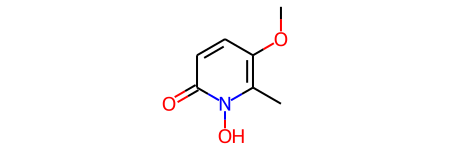

In [42]:
original_molecules[inverse['SF_0079']]